<a href="https://colab.research.google.com/github/yuhui-0611/Unstructured-Data-Analysis/blob/main/UDA_data_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# library 다운로드
!pip install pandas nltk scikit-learn

# NLTK 리소스 다운로드
import nltk

nltk.download('punkt_tab')  # tokenization에 필요한 리소스 다운로드
nltk.download('wordnet')  # lemmatization에 필요한 리소스 다운로드
nltk.download('stopwords')  # 영어 불용어 리스트 다운로드

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
import pandas as pd

df = pd.read_csv("/content/arxiv_collected_data.csv")
df = df[["abstract"]].copy()
df.head()

,abstract
0,Abstract:Factory work is a promising early sce...
1,"Abstract:Bernheim, Braghieri, Martínez-Marquin..."
2,Abstract:Web agents often revisit the same sit...
3,Abstract:Small-business owners need expert gui...
4,Abstract:Battery energy storage systems (BESSs...


In [ ]:
from nltk import word_tokenize, WordNetLemmatizer
from nltk.corpus import stopwords

# 1. Cleaning : 영문자/공백이 아닌 문자 제거
df["cleaned"] = df["abstract"].fillna("").str.replace(r"[^a-zA-Z\s]", " ", regex=True)

# 연속된 공백 정리
df["cleaned"] = df["cleaned"].str.replace(r"\s+", " ", regex=True).str.strip()

# 2. Normalization : 소문자화 + 앞뒤 공백 제거
df["normalized"] = df["cleaned"].str.lower().str.strip()

# 3. Tokenization : 문장을 단어 리스트로 분리
df["tokens"] = df["normalized"].apply(word_tokenize)

# 4. Lemmatization : 각 단어를 기본형으로 변환
df["lemmas"] = df["tokens"].apply(
    lambda toks: [WordNetLemmatizer().lemmatize(t) for t in toks])

# 5. Stopword removal : 영어 불용어와 'abstract' 제거
STOP_WORDS = set(stopwords.words("english")) | {"abstract"}

df["filtered"] = df["lemmas"].apply(
    lambda toks: [t for t in toks if t not in STOP_WORDS])

In [ ]:
# 단어 리스트를 다시 문장으로 합쳐 CSV로 저장
df["final_text"] = df["filtered"].apply(lambda toks: " ".join(toks))
df["final_text"].to_csv("arxiv_collected_data_processed.csv", index=False, header=False)

1. Cleaning (정제)
    - 영문자와 공백만 남김
    - 특수문자, 숫자 등은 제거
    - 여러 번 반복된 공백은 하나의 공백으로 정리

2. Normalization & Tokenization (정규화와 토큰화)
    - 모든 문자를 소문자로 바꿈
    - 문장을 단어 단위로 나눔
      - 예: Machine Learning Models
        → machine learning models
        → ["machine", "learning", "models"]

3. Lemmatization (표제어 추출)
    - 각 단어를 기본형, 즉 사전형으로 바꿈
      - 예: systems → system
    - 즉, 형태가 조금씩 다른 단어를 같은 단어로 취급하기 쉽게 만드는 과정

4. Stopword removal (불용어 제거)
    - the, is, and처럼 분석에 큰 의미가 없는 영어 불용어를 제거
    - 추가로 abstract라는 단어도 제거

< key functions >
- str.replace() : 특정 패턴에 해당하는 문자를 다른 문자로 바꿈
- word_tokenize() : 문장을 단어 단위로 분리
- lemmatize() : 단어를 기본형으로 변환
- stopwords.words() : 불용어 목록을 불러옴
- " ".join() : 나눠진 단어들을 다시 하나의 문장 형태로 합침

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

# 문서 x 단어 빈도 행렬
cv = CountVectorizer()
X = cv.fit_transform(df["final_text"])
terms = cv.get_feature_names_out()

# 빈도 지표 계산
TF = np.asarray(X.sum(0)).ravel()
DF = np.asarray((X > 0).sum(0)).ravel()
IDF = np.log(len(df) / DF)
TFIDF = TF * IDF

stats = pd.DataFrame({
    "term": terms,
    "TF": TF,
    "DF": DF,
    "IDF": IDF,
    "TFIDF": TFIDF
})

def top30(col):  # 지표 기준 상위 30개 단어
  return stats.sort_values(col, ascending=False).head(30)

for col in ["TF", "DF", "IDF", "TFIDF"]:
  print(f"--- {col} 상위 30 ---")
  display(top30(col)[["term", "TF", "DF", "IDF", "TFIDF"]])

--- TF 상위 30 ---


,term,TF,DF,IDF,TFIDF
1385,model,75,31,0.478036,35.852685
62,agent,46,14,1.272966,58.556421
681,economic,40,34,0.385662,15.426499
28,across,39,28,0.579818,22.612921
2025,show,37,28,0.579818,21.453284
2197,system,37,19,0.967584,35.800609
2297,two,32,22,0.820981,26.271378
69,ai,29,11,1.514128,43.909704
524,data,26,17,1.078810,28.049051
475,cost,24,9,1.714798,41.155162


--- DF 상위 30 ---


,term,TF,DF,IDF,TFIDF
681,economic,40,34,0.385662,15.426499
1385,model,75,31,0.478036,35.852685
2025,show,37,28,0.579818,21.453284
28,across,39,28,0.579818,22.612921
2297,two,32,22,0.820981,26.271378
1888,result,22,22,0.820981,18.061572
2197,system,37,19,0.967584,35.800609
524,data,26,17,1.078810,28.049051
182,based,19,16,1.139434,21.649251
918,framework,18,16,1.139434,20.509817


--- IDF 상위 30 ---


,term,TF,DF,IDF,TFIDF
2458,zuckerman,1,1,3.912023,3.912023
2454,yielded,2,1,3.912023,7.824046
1,ablating,1,1,3.912023,3.912023
2434,wise,2,1,3.912023,7.824046
2432,win,1,1,3.912023,3.912023
2428,whole,1,1,3.912023,3.912023
2425,whenever,1,1,3.912023,3.912023
2422,weighting,2,1,3.912023,7.824046
2419,weekly,2,1,3.912023,7.824046
34,activity,2,1,3.912023,7.824046


--- TFIDF 상위 30 ---


,term,TF,DF,IDF,TFIDF
62,agent,46,14,1.272966,58.556421
903,forecast,20,4,2.525729,50.514573
757,error,21,6,2.120264,44.525534
69,ai,29,11,1.514128,43.909704
331,cloud,13,2,3.218876,41.845386
475,cost,24,9,1.714798,41.155162
1871,research,17,5,2.302585,39.143947
2150,student,12,2,3.218876,38.626510
1440,network,21,8,1.832581,38.484211
2210,task,23,10,1.609438,37.017072


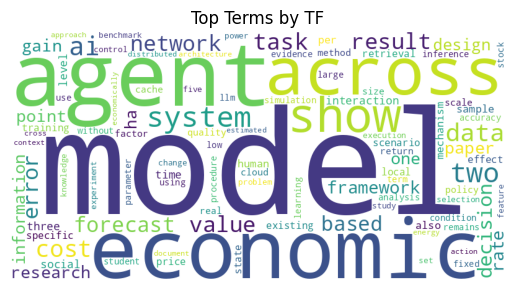

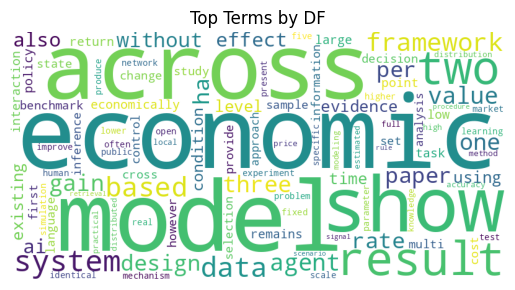

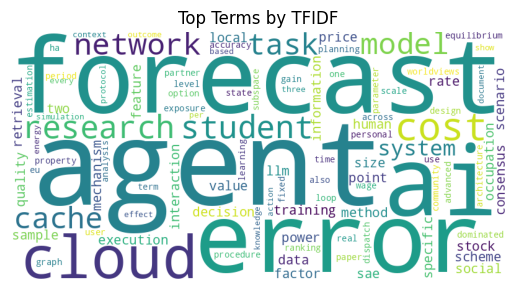

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

TOP_K = 100  # 워드클라우드 단어 수

for col in ["TF", "DF", "TFIDF"]:  # 상위 100개 단어
  top = stats.nlargest(TOP_K, col)

  freqs = dict(zip(top["term"], top[col]))  # {단어: 점수} 형태로 변환

  wc = WordCloud(width=800, height=400, background_color="white").generate_from_frequencies(freqs)

  plt.imshow(wc)
  plt.axis("off")
  plt.title(f"Top Terms by {col}")
  plt.show()

1. Document-term matrix (문서-단어 행렬)
    - 문서들에 어떤 단어들이 등장하는지 파악하고, 각 문서에서 각 단어가 몇 번 나오는지를 행렬 형태로 만듦

2. Frequency measures (빈도 지표 계산)
    - TF와 DF를 계산
    - DF를 이용해서 IDF를 계산
      - TF: 특정 단어가 전체 문서에서 얼마나 많이 나왔는지
      - DF: 특정 단어가 몇 개의 문서에 등장했는지
      - IDF: 여러 문서에 흔하게 등장하는 단어보다, 비교적 드물게 등장하는 단어에 더 높은 값을 주는 지표

3. TF-IDF
    - TF와 IDF를 결합해서 단어의 중요도를 계산
    - 단순히 많이 등장하는 단어가 아니라, 해당 문서 집합에서 상대적으로 중요한 단어를 찾는 데 사용
    - 즉, 많이 나오면서도 너무 모든 문서에 흔하게 등장하지는 않는 단어 → TF-IDF 값이 높아질 가능성이 큼

4. Word Cloud (워드클라우드)
    - 단어와 그 점수를 이용해서 워드클라우드를 만듦
    - 점수가 큰 단어일수록 더 크게 표시됨


< key functions >
- CountVectorizer() : 텍스트 문서를 단어 빈도 행렬로 바꿔주는 함수
- fit_transform() : 문서에서 사용된 단어들을 학습하고, 각 문서를 숫자 벡터 형태로 변환
- nlargest() : 값이 가장 큰 행들을 선택 > TF, DF, TF-IDF 값이 큰 상위 단어들을 뽑는 데 사용
- generate_from_frequencies() : {단어: 점수} 형태의 데이터를 이용해서 워드클라우드를 생성